# Mecanismo RRR con dos RR acoplados: dimensionado y cinemática de las patas FR y BR

Cada pata es un **RRR** (muslo, tibia y metatarso) con longitudes `r1`, `r2`, `r3`. Solo el primer eslabón del RRR tiene actuador (A1);
la tibia y el metatarso se mueven con dos mecanismos **RR** (`l1`-`l2` y `l3`-`l4`), cada uno con su actuador (A2 y A3) en el primer eslabón,
acoplados a un punto de la tibia (fracción `f1` de su longitud) y del metatarso (fracción `f2`).

El notebook hace, para cada pata:

1. **Dimensiona los RR**: calcula las longitudes mínimas de `l1`-`l4` y el punto de acople (`f1`, `f2`) para que los RR alcancen **todo el rango de movimiento del RRR**, que sale de la trayectoria de marcha del CSV.
2. Dibuja el rango alcanzable del RRR y resume los eslabones en una tabla.
3. Resuelve la **cinemática inversa** de los RR a lo largo de la trayectoria, grafica todos los ángulos y anima el mecanismo completo.

## Contenido

| Sección | Qué hace |
|---|---|
| 1. Imports | Librerías |
| 2. Modelo simbólico | Marcos, vectores y ecuaciones de cierre de lazo con sympy |
| 3. Configuración y funciones | Parámetros de la optimización y funciones reutilizables |
| 4. Pata FR | Dimensionado, rango, tabla, ángulos y animación |
| 5. Pata BR | El mismo proceso con las longitudes de la pata trasera |
| 6. Resumen | Tabla comparativa de las dos patas |

## Convenciones

- Plano x-y, ángulos positivos en sentido antihorario, 0 = eje +x. Los actuadores A1, A2, A3 están sobre el eje x (A1 en el origen, A2 a `d1` de A1, A3 a `d2` de A2).
- **Ángulos absolutos** (respecto al eje x): `alpha1 = theta1`, `alpha4 = theta2`, `alpha6 = theta3`. Son los ángulos de los tres actuadores.
- **Ángulos relativos** (respecto al eslabón anterior de su cadena): `alpha2` (rodilla) y `alpha3` (tobillo) en el RRR, `alpha5` en el RR 1 y `alpha7` en el RR 2. Es la misma convención de los marcos `orientnew` de sympy.
- El CSV (`leg_motor_angles_one_cycle.csv`) da la orientación **absoluta** del muslo, la tibia y el metatarso en convención MuJoCo (0 = colgando vertical, positivo = hacia atrás). Se convierte con `alpha = -90° - motor`.

## Supuestos (revisar)

- `X_FORWARD = True`: el eje x del mecanismo (hacia donde están A2 y A3) apunta hacia adelante del robot.
- La pata BR usa la misma separación entre actuadores (`d1`, `d2`) que la FR, porque no se indicó otra.
- Cada RR se dimensiona por separado, con eslabones iguales (`ra = rb`) y una holgura `MARGEN` respecto al brazo totalmente estirado.

## 1. Imports

Sympy para el modelo simbólico, NumPy/Pandas para los cálculos y la lectura del CSV, y Matplotlib para las gráficas y la animación.

In [1]:
import sympy
from sympy import symbols, solve
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, least_squares
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

## 2. Modelo simbólico

Define los símbolos, los parámetros conocidos de cada pata (`paramsfront`, `paramsrear`), los marcos de referencia, los vectores de los eslabones y las **ecuaciones de cierre de lazo**:

- `eq1`: el RR 1 (`l1`, `l2`) cierra el lazo con el punto de la tibia a la fracción `f1`.
- `eq2`: el RR 2 (`l3`, `l4`) cierra el lazo con el punto del metatarso a la fracción `f2`.

`eqkin` son las 4 ecuaciones escalares (x e y de cada lazo). `theta1`, `theta2`, `theta3` son los actuadores y `alpha2`, `alpha3`, `alpha5`, `alpha7` las incógnitas pasivas. Los valores de `l1` a `l4` y de `f1`, `f2` que se usarán en el diseño salen del dimensionado de las secciones 4 y 5, no de esta celda.

In [2]:
l1,l2,l3,l4,r1,r2,r3,d1,d2 = symbols('l1 l2 l3 l4 r1 r2 r3 d1 d2')
t = symbols('t')  # tiempo

#Fraccion de la longitud de los eslabones 2 y 3 del rrr para acoplar los mecanismos RR
f1 = 0.5  # fraccion de la longitud del eslabon 2 del RRR principal para acoplar el primer RR
f2 = 0.5  # fraccion de la longitud del eslabon 3 del RRR principal para acoplar el segundo RR

# theta: angulos de los 3 actuadores (solo el primer eslabon de cada mecanismo tiene motor)
theta1, theta2, theta3 = dynamicsymbols('theta1 theta2 theta3')

#Parametros conocidos del sistema (longitudes del RRR: muslo, tibia, metatarso; separacion entre actuadores)
paramsfront={r1: 0.121, r2: 0.111, r3: 0.1534, d1: 0.084, d2: 0.097}
paramsrear ={r1: 0.166, r2: 0.231, r3: 0.148,  d1: 0.084, d2: 0.097}   # d1, d2 supuestos iguales a los de la pata FR

# alpha: angulos de los eslabones, con la misma convencion de los marcos de abajo (orientnew):
#   RRR principal:                alpha1 (absoluto), alpha2 (relativo a alpha1), alpha3 (relativo a alpha2)
#   RR acoplado al eslabon 2:     alpha4 (absoluto), alpha5 (relativo a alpha4)
#   RR acoplado al eslabon 3:     alpha6 (absoluto), alpha7 (relativo a alpha6)
# Los primeros eslabones de cada mecanismo van directo al actuador:
alpha1, alpha4, alpha6 = theta1, theta2, theta3
# Eslabones libres (sin actuador)
alpha2, alpha3, alpha5, alpha7 = dynamicsymbols('alpha2 alpha3 alpha5 alpha7')

N=ReferenceFrame('N')  # marco inicial
#RRR principal
A=N.orientnew('A', 'Axis', [alpha1, N.z])  # marco del primer eslabon
B=A.orientnew('B', 'Axis', [alpha2, A.z])  # marco del segundo eslabon
C=B.orientnew('C', 'Axis', [alpha3, B.z])  # marco del tercer eslabon
#Primer RR acoplado al eslabon 2
D=N.orientnew('D', 'Axis', [alpha4, N.z])  # marco del primer eslabon
E=D.orientnew('E', 'Axis', [alpha5, D.z])  # marco del segundo eslabon
#Segundo RR acoplado al eslabon 3
F=N.orientnew('F', 'Axis', [alpha6, N.z])  #marco del primer eslabon
G=F.orientnew('G', 'Axis', [alpha7, F.z])  # marco del segundo eslabon

#Eslabones
r1 = r1 * A.x  # vector de posicion del primer eslabon del RRR principal
r2 = r2 * B.x  # vector de posicion del segundo eslabon del RRR principal
r3 = r3 * C.x  # vector de posicion del tercer eslabon del RRR principal
l1 = l1 * D.x  # vector de posicion del primer eslabon del RR acoplado al eslabon 2
l2 = l2 * E.x  # vector de posicion del segundo eslabon del RR acoplado al eslabon 2
l3 = l3 * F.x  # vector de posicion del primer eslabon del RR acoplado al eslabon 3
l4 = l4 * G.x  # vector de posicion del segundo eslabon del RR acoplado al eslabon 3
d1 = d1 * N.x  # vector de posicion del primer eslabon del RR acoplado al eslabon 2
d2 = d2 * N.x  # vector de posicion del primer eslabon del RR acoplado al eslabon 3

#Loops de cierre
eq1=r1+f1*r2-l1-l2-d1  # loop de cierre del primer RR acoplado al eslabon 2
eq2=r1+r2+f2*r3-l3-l4-(d1+d2)  # loop de cierre del segundo RR acoplado al eslabon 3

P=r1+r2+r3  # posicion del efector final del RRR principal

#Ecuaciones de forma matricial
eqkin=sympy.Matrix([eq1.dot(N.x), eq1.dot(N.y), eq2.dot(N.x), eq2.dot(N.y)])
eqkin_fun=sympy.lambdify([theta1, theta2, theta3], eqkin)
myfun = lambda x: eqkin_fun(x[0], x[1], x[2])

## 3. Configuración y funciones

### 3.1 Parámetros de la optimización

Todos se pueden editar y valen para las dos patas:

| Parámetro | Significado |
|---|---|
| `CSV_PATH` | CSV con la trayectoria de marcha (orientación absoluta de muslo, tibia y metatarso de cada pata) |
| `X_FORWARD` | `True` si el eje x del mecanismo apunta hacia adelante del robot; `False` espeja la pata |
| `AMPLIAR_DEG` | Holgura extra, en grados, del rango de movimiento del RRR respecto al del CSV |
| `MARGEN` | Holgura relativa respecto al brazo de un RR totalmente estirado |
| `F_MIN` | Límite inferior de `f`: con `f` chico el RR casi no tiene brazo de palanca sobre el eslabón |
| `BRANCH` | Rama del codo de los RR en la cinemática inversa (+1 o -1) |

In [3]:
CSV_PATH = Path("leg_motor_angles_one_cycle.csv")   # junto al notebook
X_FORWARD = True     # SUPUESTO: el eje x del mecanismo (hacia donde estan A2 y A3) apunta hacia adelante del robot
AMPLIAR_DEG = 0.0    # holgura extra del rango del RRR [deg]
MARGEN = 0.05        # holgura respecto a brazo totalmente estirado
F_MIN = 0.2          # limite inferior de f (punto de acople)
BRANCH = +1          # rama del codo de los RR (+1 / -1)

u = lambda a: np.stack([np.cos(a), np.sin(a)], axis=-1)   # vector unitario de angulo a

### 3.2 Dimensionado de los RR

`dimensionar_pata` hace todo el cálculo de una pata y devuelve un diccionario con los resultados:

1. Lee la pata del CSV y convierte las orientaciones absolutas de muslo, tibia y metatarso (convención MuJoCo) a `alpha1`, `alpha2`, `alpha3` del plano del mecanismo.
2. Define el **rango de movimiento del RRR** como la caja que contiene toda la trayectoria: `alpha1`, `q2 = alpha2 - alpha1` (rodilla) y `q3 = alpha3 - alpha2` (tobillo), más `AMPLIAR_DEG`.
3. Para cada `f` entre `F_MIN` y 0.5 calcula, sobre una rejilla de poses del RRR (que incluye las esquinas del rango), la distancia máxima `Dmax` entre cada actuador y su punto de acople.
4. Un RR de eslabones `ra`, `rb` alcanza el punto solo si `|ra - rb| <= D <= ra + rb`. Para cubrir todo el rango basta `ra + rb >= (1 + MARGEN)·Dmax`. La suma mínima se reparte en partes iguales (`ra = rb`), que además cumple siempre la cota inferior.
5. Elige para cada RR el `f` que da la menor longitud total (`f1_opt`, `f2_opt`) y comprueba el resultado con 50 000 poses aleatorias del rango.

In [4]:
def dimensionar_pata(nombre, leg, params, csv_path=CSV_PATH, x_forward=X_FORWARD,
                     ampliar_deg=AMPLIAR_DEG, margen=MARGEN, f_min=F_MIN, n_g=25):
    # Valores numericos (los simbolos r1, r2, r3, d1, d2 ya son vectores de sympy: se leen las llaves por nombre)
    p = {k.name: v for k, v in params.items()}
    R1, R2, R3 = p['r1'], p['r2'], p['r3']
    A1 = np.array([0.0, 0.0])
    A2 = np.array([p['d1'], 0.0])
    A3 = np.array([p['d1'] + p['d2'], 0.0])

    # --- Trayectoria del CSV: orientacion ABSOLUTA de muslo, tibia y metatarso ---
    df = pd.read_csv(csv_path)
    t_csv = df['time_s'].to_numpy()
    mot = np.deg2rad(df[[f'{leg}_hip_motor', f'{leg}_knee_motor', f'{leg}_ankle_motor']].to_numpy())
    ang = -np.pi / 2 + (-1 if x_forward else 1) * mot        # MuJoCo -> plano del mecanismo; columnas: orientacion absoluta de los eslabones 1, 2, 3
    q_csv = np.column_stack([ang[:, 0], ang[:, 1] - ang[:, 0], ang[:, 2] - ang[:, 1]])   # alpha1, alpha2 (rodilla), alpha3 (tobillo)

    # --- Rango de movimiento del RRR: caja que contiene toda la trayectoria ---
    ext = np.deg2rad(ampliar_deg)
    th1_rng, q2_rng, q3_rng = [np.array([q_csv[:, k].min() - ext, q_csv[:, k].max() + ext]) for k in range(3)]
    print(f"[{nombre}] Rango del RRR [deg]:  alpha1 = {np.rad2deg(th1_rng).round(1)}  "
          f"alpha2 = {np.rad2deg(q2_rng).round(1)}  alpha3 = {np.rad2deg(q3_rng).round(1)}")

    # --- Rejilla de poses del RRR (incluye las esquinas del rango) ---
    G1, Gq2, Gq3 = np.meshgrid(*[np.linspace(*r, n_g) for r in (th1_rng, q2_rng, q3_rng)], indexing='ij')
    b1 = G1.ravel(); b2 = b1 + Gq2.ravel(); b3 = b2 + Gq3.ravel()
    Jg1 = A1 + R1 * u(b1)
    Jg2 = Jg1 + R2 * u(b2)

    # --- Barrido de f: longitud total minima (ra + rb) de cada RR ---
    f_grid = np.round(np.arange(f_min, 0.5001, 0.05), 3)
    Ltot1 = np.zeros(len(f_grid)); Ltot2 = np.zeros(len(f_grid))
    for i, fv in enumerate(f_grid):
        Dg2 = np.linalg.norm(Jg1 + fv * R2 * u(b2) - A2, axis=1)    # actuador 2 -> acople en el eslabon 2
        Dg3 = np.linalg.norm(Jg2 + fv * R3 * u(b3) - A3, axis=1)    # actuador 3 -> acople en el eslabon 3
        Ltot1[i] = (1 + margen) * Dg2.max()
        Ltot2[i] = (1 + margen) * Dg3.max()
    i1, i2 = Ltot1.argmin(), Ltot2.argmin()
    f1_opt, f2_opt = f_grid[i1], f_grid[i2]
    l1_opt = l2_opt = Ltot1[i1] / 2
    l3_opt = l4_opt = Ltot2[i2] / 2

    print(f"[{nombre}]    f    | ra+rb RR1 [m] | ra+rb RR2 [m]")
    for fv, a, b in zip(f_grid, Ltot1, Ltot2):
        print(f"[{nombre}]  {fv:5.2f}  |    {a:.4f}     |    {b:.4f}")
    print(f"[{nombre}] RR 1 (eslabon 2): f1={f1_opt:.2f}, l1={l1_opt:.4f}, l2={l2_opt:.4f}")
    print(f"[{nombre}] RR 2 (eslabon 3): f2={f2_opt:.2f}, l3={l3_opt:.4f}, l4={l4_opt:.4f}")

    # --- Comprobacion con poses aleatorias del rango (no solo la rejilla) ---
    rng = np.random.default_rng(0)
    Ns = 50000
    a1 = rng.uniform(*th1_rng, Ns)
    a2 = a1 + rng.uniform(*q2_rng, Ns)
    a3 = a2 + rng.uniform(*q3_rng, Ns)
    J1 = A1 + R1 * u(a1)
    J2 = J1 + R2 * u(a2)
    Pe = J2 + R3 * u(a3)                                  # extremo del RRR (efector final)
    D2 = np.linalg.norm(J1 + f1_opt * R2 * u(a2) - A2, axis=1)
    D3 = np.linalg.norm(J2 + f2_opt * R3 * u(a3) - A3, axis=1)
    alcanzable = lambda Dk, ra, rb: (Dk >= abs(ra - rb)) & (Dk <= ra + rb)
    ok_all = alcanzable(D2, l1_opt, l2_opt) & alcanzable(D3, l3_opt, l4_opt)
    print(f"[{nombre}] Poses aleatorias del rango alcanzables por los dos RR: {100*ok_all.mean():.1f} %")

    return dict(nombre=nombre, leg=leg, p=p, R=(R1, R2, R3), A=(A1, A2, A3), t_csv=t_csv, ang=ang, q_csv=q_csv,
                rangos=(th1_rng, q2_rng, q3_rng), f_grid=f_grid, Ltot1=Ltot1, Ltot2=Ltot2, i1=i1, i2=i2,
                f1_opt=f1_opt, f2_opt=f2_opt, l=(l1_opt, l2_opt, l3_opt, l4_opt),
                Pe=Pe, ok_all=ok_all, idx=rng.choice(Ns, 15000, replace=False), D2=D2, D3=D3)

### 3.3 Gráficas del dimensionado y del rango

- `graficar_dimensionado`: a la izquierda, la longitud mínima `ra + rb` de cada RR contra `f` (la estrella marca el elegido); a la derecha, la distribución de la distancia `D` actuador-acople contra la banda que el RR alcanza (`|ra - rb|` a `ra + rb`).
- `graficar_rango`: dibuja el RRR en las 8 esquinas de su rango (azul) y en la pose central (rojo), sobre la nube de puntos que alcanza el extremo. Verde indica poses que los dos RR pueden seguir; gris, las que no.
- `tabla_eslabones`: resume los eslabones fijos del RRR y los optimizados de los RR.

In [5]:
def graficar_dimensionado(res):
    f_grid, Ltot1, Ltot2, i1, i2 = res['f_grid'], res['Ltot1'], res['Ltot2'], res['i1'], res['i2']
    l1_opt, l2_opt, l3_opt, l4_opt = res['l']
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
    axs[0].plot(f_grid, Ltot1, 'o-', label='RR 1 (eslabon 2)'); axs[0].plot(f_grid, Ltot2, 's-', label='RR 2 (eslabon 3)')
    axs[0].plot(res['f1_opt'], Ltot1[i1], 'k*', ms=12); axs[0].plot(res['f2_opt'], Ltot2[i2], 'k*', ms=12)
    axs[0].set_xlabel('f (punto de acople)'); axs[0].set_ylabel('ra + rb [m]'); axs[0].grid(alpha=0.3); axs[0].legend()
    axs[0].set_title(f"Pata {res['nombre']}: longitud minima vs punto de acople")
    for ax, Dk, (ra, rb), nm in zip(axs[1:], (res['D2'], res['D3']), ((l1_opt, l2_opt), (l3_opt, l4_opt)), ("RR 1", "RR 2")):
        ax.hist(Dk, bins=60, color='tab:blue', alpha=0.7)
        ax.axvspan(abs(ra - rb), ra + rb, color='tab:green', alpha=0.2, label='D alcanzable (|ra-rb| .. ra+rb)')
        ax.set_title(nm); ax.set_xlabel('D (actuador - punto de acople) [m]'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


def graficar_rango(res):
    R1, R2, R3 = res['R']; A1, A2, A3 = res['A']
    th1_rng, q2_rng, q3_rng = res['rangos']
    Pe, ok_all, idx = res['Pe'], res['ok_all'], res['idx']

    def draw_rrr(ax, th1, q2, q3, **kw):
        b1 = th1; b2 = b1 + q2; b3 = b2 + q3
        j1 = A1 + R1 * u(b1); j2 = j1 + R2 * u(b2); j3 = j2 + R3 * u(b3)
        pts = np.array([A1, j1, j2, j3])
        ax.plot(pts[:, 0], pts[:, 1], '-o', ms=5, **kw)

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(*Pe[idx].T, s=1, c='lightgray')                                  # gris = rango del RRR
    ax.scatter(*Pe[idx][ok_all[idx]].T, s=1, c='tab:green', alpha=0.5)           # verde = alcanzable con los dos RR
    for th1v in th1_rng:                                                         # esquinas del rango (tenues)
        for q2v in q2_rng:
            for q3v in q3_rng:
                draw_rrr(ax, th1v, q2v, q3v, color='tab:blue', alpha=0.35, lw=1.5)
    draw_rrr(ax, th1_rng.mean(), q2_rng.mean(), q3_rng.mean(), color='tab:red', lw=3.5, label='pose central')
    for Ak, nm in zip((A1, A2, A3), ('A1', 'A2', 'A3')):
        ax.plot(*Ak, 's', color='k', ms=9)
        ax.annotate(nm, Ak, (Ak[0], Ak[1] - 0.02), ha='center')
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
    ax.set_title(f"Pata {res['nombre']}: RRR en las esquinas del rango (azul) y pose central (rojo)\n"
                 "nube del extremo: rango del RRR (gris) / alcanzable con los RR (verde)")
    ax.legend()
    plt.tight_layout(); plt.show()


def tabla_eslabones(res):
    R1, R2, R3 = res['R']; l1_opt, l2_opt, l3_opt, l4_opt = res['l']
    tabla = pd.DataFrame([
        # (eslabon, mecanismo, tipo, longitud [m], punto de acople f)
        ('r1', 'RRR principal (eslabon 1)',   'fijo',       R1,     None),
        ('r2', 'RRR principal (eslabon 2)',   'fijo',       R2,     None),
        ('r3', 'RRR principal (eslabon 3)',   'fijo',       R3,     None),
        ('l1', 'RR 1, acoplado al eslabon 2', 'optimizado', l1_opt, res['f1_opt']),
        ('l2', 'RR 1, acoplado al eslabon 2', 'optimizado', l2_opt, res['f1_opt']),
        ('l3', 'RR 2, acoplado al eslabon 3', 'optimizado', l3_opt, res['f2_opt']),
        ('l4', 'RR 2, acoplado al eslabon 3', 'optimizado', l4_opt, res['f2_opt']),
    ], columns=['eslabon', 'mecanismo', 'tipo', 'longitud [m]', 'f (acople)'])
    tabla['longitud [mm]'] = (tabla['longitud [m]'] * 1000).round(1)
    tabla['longitud [m]'] = tabla['longitud [m]'].round(4)
    tabla.insert(0, 'pata', res['nombre'])
    p = res['p']
    print(f"Pata {res['nombre']}: d1 = {p['d1']*1000:.1f} mm (A1-A2), d2 = {p['d2']*1000:.1f} mm (A2-A3); "
          f"longitud total de los eslabones optimizados: {tabla.loc[tabla.tipo == 'optimizado', 'longitud [m]'].sum()*1000:.1f} mm")
    return tabla

### 3.4 Trayectoria, ángulos y animación

- `resolver_trayectoria`: con el RRR siguiendo el CSV (`alpha1`, `alpha2`, `alpha3`), calcula los puntos de acople y resuelve cada RR por **cinematica inversa** (`rr_ik`, ley de cosenos) para obtener `theta2 = alpha4`, `theta3 = alpha6`, `alpha5` y `alpha7`. Informa si todos los puntos son alcanzables y qué tan cerca del brazo estirado quedan (1.00 = estirado).
- `graficar_angulos`: seis paneles con los ángulos de los actuadores, del RRR, del RR 1, del RR 2, la orientación absoluta de los eslabones del RRR y la posición del extremo.
- `animar`: anima el mecanismo completo (RRR en azul, RR 1 en naranja, RR 2 en verde, puntos de acople en rojo) con la estela del extremo, y guarda un GIF junto al notebook.

In [6]:
def rr_ik(Aact, Pt, ra, rb, branch):
    # RR con base en Aact y extremo en Pt (ley de cosenos).
    # Devuelve (angulo absoluto del 1er eslabon, angulo absoluto del 2do eslabon, codo, alcanzable).
    v = Pt - Aact
    Dk = np.linalg.norm(v, axis=1)
    c = (ra**2 + Dk**2 - rb**2) / (2 * ra * Dk)
    reach = np.abs(c) <= 1
    phi = np.arctan2(v[:, 1], v[:, 0]) + branch * np.arccos(np.clip(c, -1, 1))
    K = Aact + ra * u(phi)
    beta = np.arctan2(*(Pt - K).T[::-1])
    return phi, beta, K, reach


def resolver_trayectoria(res, branch=BRANCH):
    R1, R2, R3 = res['R']; A1, A2, A3 = res['A']; ang, q_csv = res['ang'], res['q_csv']
    l1_opt, l2_opt, l3_opt, l4_opt = res['l']
    f1_opt, f2_opt = res['f1_opt'], res['f2_opt']
    # Posiciones del RRR y puntos de acople (ang = orientaciones absolutas de los eslabones)
    J1c = A1 + R1 * u(ang[:, 0])
    J2c = J1c + R2 * u(ang[:, 1])
    J3c = J2c + R3 * u(ang[:, 2])                         # extremo del RRR
    Q2c = J1c + f1_opt * R2 * u(ang[:, 1])
    Q3c = J2c + f2_opt * R3 * u(ang[:, 2])
    phi2, beta2, K2c, reach2 = rr_ik(A2, Q2c, l1_opt, l2_opt, branch)    # phi2 = alpha4 (absoluto)
    phi3, beta3, K3c, reach3 = rr_ik(A3, Q3c, l3_opt, l4_opt, branch)    # phi3 = alpha6 (absoluto)
    print(f"[{res['nombre']}] Puntos de la trayectoria alcanzables: RR1 {100*reach2.mean():.0f} %, RR2 {100*reach3.mean():.0f} %")
    print(f"[{res['nombre']}] Distancia maxima / alcance: RR1 {np.linalg.norm(Q2c - A2, axis=1).max() / (l1_opt + l2_opt):.2f}, "
          f"RR2 {np.linalg.norm(Q3c - A3, axis=1).max() / (l3_opt + l4_opt):.2f}   (1.00 = brazo estirado)")
    # Angulos con la convencion de sympy [deg], continuos en el ciclo
    rel = lambda a, b: np.unwrap(np.angle(np.exp(1j * (a - b))))          # angulo de a respecto a b
    angles = {
        'theta1 = alpha1': ang[:, 0],                     # cadera (absoluto)
        'alpha2': q_csv[:, 1],                            # rodilla (relativo al eslabon 1)
        'alpha3': q_csv[:, 2],                            # tobillo (relativo al eslabon 2)
        'theta2 = alpha4': phi2,                          # actuador 2 (absoluto)
        'alpha5': rel(beta2, phi2),                       # 2do eslabon del RR 1 (relativo a alpha4)
        'theta3 = alpha6': phi3,                          # actuador 3 (absoluto)
        'alpha7': rel(beta3, phi3),                       # 2do eslabon del RR 2 (relativo a alpha6)
    }
    angles = {k: np.rad2deg(np.unwrap(v)) for k, v in angles.items()}
    return dict(J1c=J1c, J2c=J2c, J3c=J3c, Q2c=Q2c, Q3c=Q3c, K2c=K2c, K3c=K3c, angles=angles)


def graficar_angulos(res, sol):
    t_csv, ang, angles, J3c = res['t_csv'], res['ang'], sol['angles'], sol['J3c']
    fig, axs = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
    def plot_group(ax, keys, title):
        for k in keys:
            ax.plot(t_csv, angles[k], label=k)
        ax.set_title(title); ax.set_ylabel('[deg]'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plot_group(axs[0, 0], ['theta1 = alpha1', 'theta2 = alpha4', 'theta3 = alpha6'], 'Actuadores (theta, absolutos)')
    plot_group(axs[0, 1], ['theta1 = alpha1', 'alpha2', 'alpha3'], 'RRR: cadera, rodilla, tobillo (alpha2 y alpha3 relativos)')
    plot_group(axs[1, 0], ['theta2 = alpha4', 'alpha5'], 'RR 1 (alpha5 relativo a alpha4)')
    plot_group(axs[1, 1], ['theta3 = alpha6', 'alpha7'], 'RR 2 (alpha7 relativo a alpha6)')
    for k, nm in enumerate(('eslabon 1', 'eslabon 2', 'eslabon 3')):
        axs[2, 0].plot(t_csv, np.rad2deg(np.unwrap(ang[:, k])), label=nm)
    axs[2, 0].set_title('Orientacion absoluta de los eslabones del RRR'); axs[2, 0].set_ylabel('[deg]'); axs[2, 0].grid(alpha=0.3); axs[2, 0].legend(fontsize=8)
    axs[2, 1].plot(t_csv, J3c[:, 0], label='x'); axs[2, 1].plot(t_csv, J3c[:, 1], label='y')
    axs[2, 1].set_title('Extremo del RRR'); axs[2, 1].set_ylabel('[m]'); axs[2, 1].grid(alpha=0.3); axs[2, 1].legend(fontsize=8)
    for ax in axs[2]: ax.set_xlabel('t [s]')
    fig.suptitle(f"Pata {res['nombre']}")
    plt.tight_layout(); plt.show()


def animar(res, sol, gif=None):
    A1, A2, A3 = res['A']; t_csv = res['t_csv']
    J1c, J2c, J3c, Q2c, Q3c, K2c, K3c = (sol[k] for k in ('J1c', 'J2c', 'J3c', 'Q2c', 'Q3c', 'K2c', 'K3c'))
    allpts = np.vstack([J1c, J2c, J3c, K2c, K3c, A1[None], A2[None], A3[None]])
    pad = 0.03
    fig, ax = plt.subplots(figsize=(6, 6))
    def draw_frame(i):
        ax.cla()
        ax.set_aspect('equal'); ax.grid(alpha=0.3)
        ax.set_xlim(allpts[:, 0].min() - pad, allpts[:, 0].max() + pad)
        ax.set_ylim(allpts[:, 1].min() - pad, allpts[:, 1].max() + pad)
        ax.plot(*J3c[:i + 1].T, color='gray', lw=1, alpha=0.6)                        # estela del extremo
        seg = lambda pts, c: ax.plot(*np.array(pts).T, '-o', color=c, lw=3, ms=5)
        seg([A1, J1c[i], J2c[i], J3c[i]], 'tab:blue')                                  # RRR
        seg([A2, K2c[i], Q2c[i]], 'tab:orange')                                        # RR 1
        seg([A3, K3c[i], Q3c[i]], 'tab:green')                                         # RR 2
        ax.plot(*np.array([Q2c[i], Q3c[i]]).T, 'o', color='red', ms=6, zorder=5)       # puntos de acople
        ax.plot(*np.array([A1, A2, A3]).T, 's', color='k', ms=9)
        ax.set_title(f"Pata {res['nombre']}  t = {t_csv[i]:.3f} s")
        ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
    anim = FuncAnimation(fig, draw_frame, frames=len(t_csv), interval=40, repeat=True)
    anim.save(Path(gif or f"mecanismo_{res['leg']}.gif"), writer=PillowWriter(fps=25))
    plt.close(fig)
    return HTML(anim.to_jshtml())

## 4. Pata FR

Pata delantera derecha. Longitudes del RRR: `r1 = 0.121`, `r2 = 0.111`, `r3 = 0.1534` m (`paramsfront`).

### 4.1 Dimensionado de los RR

Lee las columnas `fr_hip_motor`, `fr_knee_motor` y `fr_ankle_motor` del CSV, define el rango del RRR, barre el punto de acople `f` y calcula las longitudes mínimas de `l1`-`l4`. Imprime el rango, la tabla de longitud contra `f` y el resultado.

In [7]:
res_fr = dimensionar_pata('FR', 'fr', paramsfront)

[FR] Rango del RRR [deg]:  alpha1 = [-149.2 -128.9]  alpha2 = [ 91.4 130.3]  alpha3 = [-147.4  -64.4]
[FR]    f    | ra+rb RR1 [m] | ra+rb RR2 [m]
[FR]   0.20  |    0.2034     |    0.3202
[FR]   0.25  |    0.2027     |    0.3282
[FR]   0.30  |    0.2022     |    0.3363
[FR]   0.35  |    0.2018     |    0.3443
[FR]   0.40  |    0.2016     |    0.3524
[FR]   0.45  |    0.2016     |    0.3604
[FR]   0.50  |    0.2017     |    0.3685
[FR] RR 1 (eslabon 2): f1=0.45, l1=0.1008, l2=0.1008
[FR] RR 2 (eslabon 3): f2=0.20, l3=0.1601, l4=0.1601
[FR] Poses aleatorias del rango alcanzables por los dos RR: 100.0 %


### 4.2 Gráficas del dimensionado

Longitud mínima de cada RR contra `f` (con el `f` elegido marcado) y distancia actuador-acople contra la banda alcanzable.

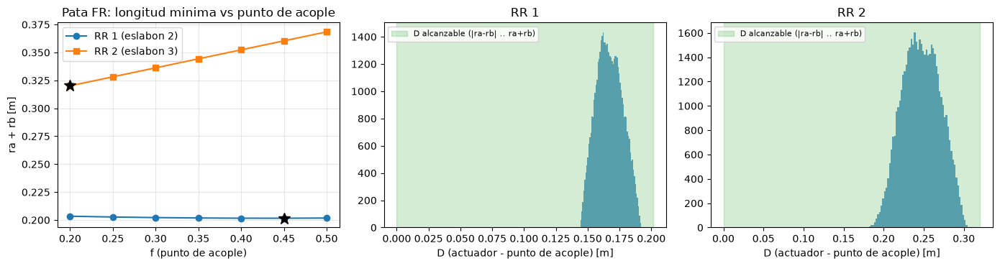

In [8]:
graficar_dimensionado(res_fr)

### 4.3 Rango alcanzable del RRR

El RRR dibujado en las esquinas de su rango de movimiento y en la pose central, sobre la nube de puntos que alcanza su extremo. Verde: poses que los dos RR pueden seguir.

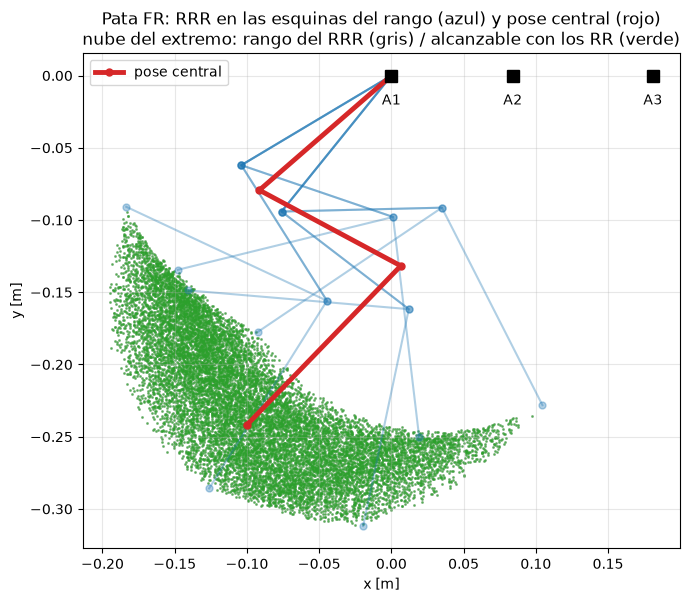

In [9]:
graficar_rango(res_fr)

### 4.4 Tabla de eslabones

Eslabones fijos del RRR (`r1`, `r2`, `r3`) y eslabones optimizados de los RR (`l1` a `l4`), con el punto de acople `f` de cada RR.

In [10]:
tabla_fr = tabla_eslabones(res_fr)
tabla_fr

Pata FR: d1 = 84.0 mm (A1-A2), d2 = 97.0 mm (A2-A3); longitud total de los eslabones optimizados: 521.8 mm


,pata,eslabon,mecanismo,tipo,longitud [m],f (acople),longitud [mm]
0,FR,r1,RRR principal (eslabon 1),fijo,0.1210,NaN,121.0
1,FR,r2,RRR principal (eslabon 2),fijo,0.1110,NaN,111.0
2,FR,r3,RRR principal (eslabon 3),fijo,0.1534,NaN,153.4
3,FR,l1,"RR 1, acoplado al eslabon 2",optimizado,0.1008,0.45,100.8
4,FR,l2,"RR 1, acoplado al eslabon 2",optimizado,0.1008,0.45,100.8
5,FR,l3,"RR 2, acoplado al eslabon 3",optimizado,0.1601,0.20,160.1
6,FR,l4,"RR 2, acoplado al eslabon 3",optimizado,0.1601,0.20,160.1


### 4.5 Trayectoria del CSV y ángulos

El RRR sigue la trayectoria de la pata FR y se resuelven los dos RR por cinemática inversa. Muestra los ángulos de los tres actuadores (`theta1`, `theta2`, `theta3`) y de los eslabones libres (`alpha2`, `alpha3`, `alpha5`, `alpha7`).

[FR] Puntos de la trayectoria alcanzables: RR1 100 %, RR2 100 %
[FR] Distancia maxima / alcance: RR1 0.87, RR2 0.83   (1.00 = brazo estirado)


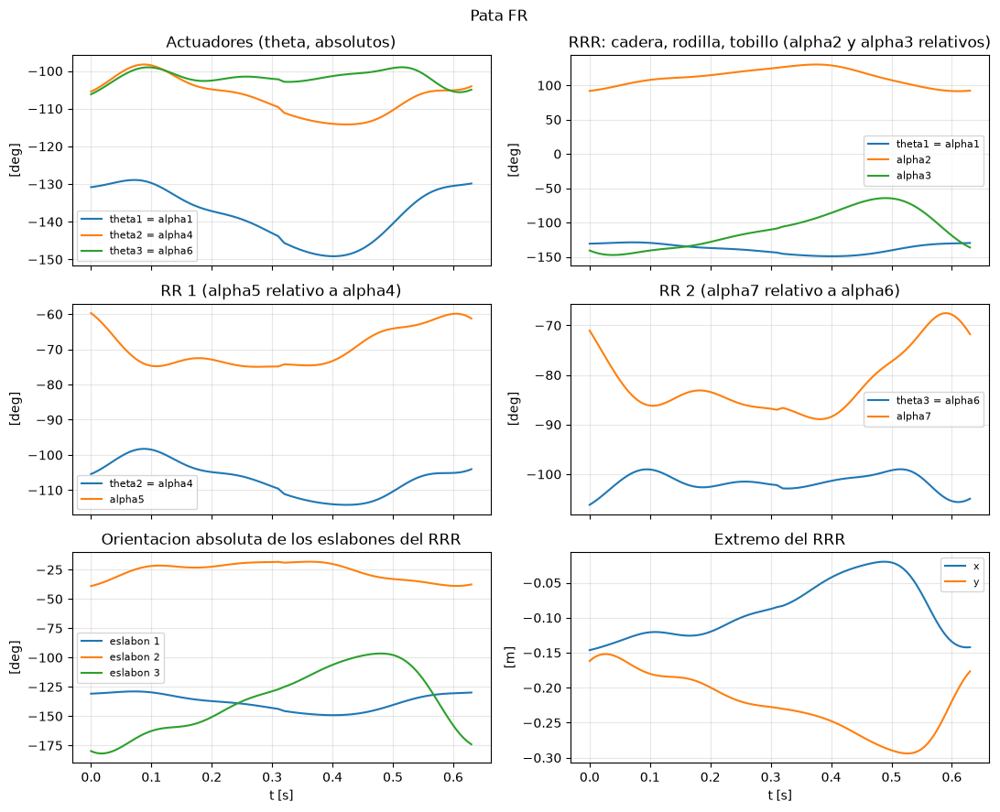

In [11]:
sol_fr = resolver_trayectoria(res_fr)
graficar_angulos(res_fr, sol_fr)

### 4.6 Animación

Animación del mecanismo completo siguiendo la trayectoria. Se guarda también como `mecanismo_fr.gif` junto al notebook.

In [12]:
animar(res_fr, sol_fr)

## 5. Pata BR

Pata trasera derecha. Longitudes del RRR: `r1 = 0.166`, `r2 = 0.231`, `r3 = 0.148` m (`paramsrear`). **Supuesto:** la separación entre actuadores (`d1 = 84 mm`, `d2 = 97 mm`) es la misma que en la pata FR.

### 5.1 Dimensionado de los RR

Lee las columnas `br_hip_motor`, `br_knee_motor` y `br_ankle_motor` del CSV, define el rango del RRR, barre el punto de acople `f` y calcula las longitudes mínimas de `l1`-`l4`. Imprime el rango, la tabla de longitud contra `f` y el resultado.

In [13]:
res_br = dimensionar_pata('BR', 'br', paramsrear)

[BR] Rango del RRR [deg]:  alpha1 = [-49.9 -36.8]  alpha2 = [-123.2  -93.7]  alpha3 = [30.8 79.9]
[BR]    f    | ra+rb RR1 [m] | ra+rb RR2 [m]
[BR]   0.20  |    0.1629     |    0.4183
[BR]   0.25  |    0.1712     |    0.4256
[BR]   0.30  |    0.1799     |    0.4329
[BR]   0.35  |    0.1890     |    0.4402
[BR]   0.40  |    0.1985     |    0.4476
[BR]   0.45  |    0.2082     |    0.4549
[BR]   0.50  |    0.2181     |    0.4623
[BR] RR 1 (eslabon 2): f1=0.20, l1=0.0814, l2=0.0814
[BR] RR 2 (eslabon 3): f2=0.20, l3=0.2091, l4=0.2091
[BR] Poses aleatorias del rango alcanzables por los dos RR: 100.0 %


### 5.2 Gráficas del dimensionado

Longitud mínima de cada RR contra `f` (con el `f` elegido marcado) y distancia actuador-acople contra la banda alcanzable.

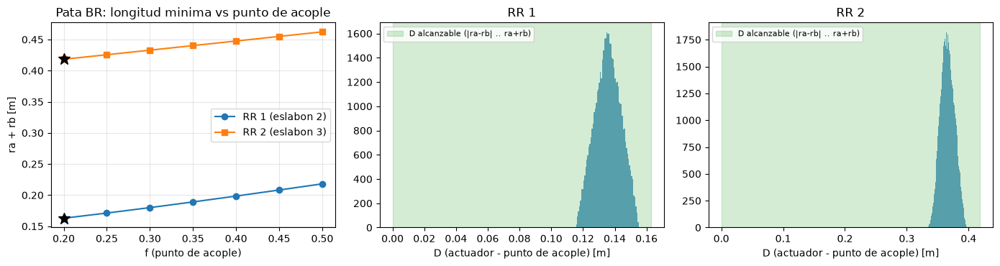

In [14]:
graficar_dimensionado(res_br)

### 5.3 Rango alcanzable del RRR

El RRR dibujado en las esquinas de su rango de movimiento y en la pose central, sobre la nube de puntos que alcanza su extremo. Verde: poses que los dos RR pueden seguir.

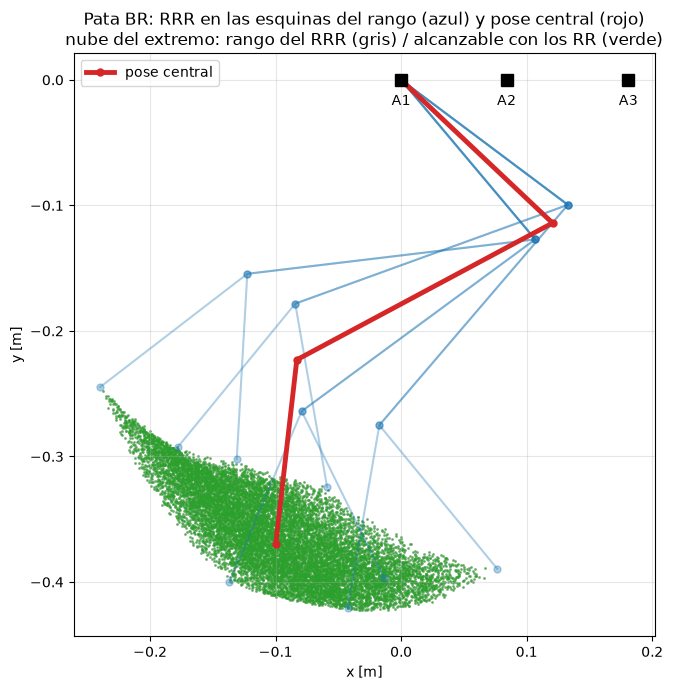

In [15]:
graficar_rango(res_br)

### 5.4 Tabla de eslabones

Eslabones fijos del RRR (`r1`, `r2`, `r3`) y eslabones optimizados de los RR (`l1` a `l4`), con el punto de acople `f` de cada RR.

In [16]:
tabla_br = tabla_eslabones(res_br)
tabla_br

Pata BR: d1 = 84.0 mm (A1-A2), d2 = 97.0 mm (A2-A3); longitud total de los eslabones optimizados: 581.0 mm


,pata,eslabon,mecanismo,tipo,longitud [m],f (acople),longitud [mm]
0,BR,r1,RRR principal (eslabon 1),fijo,0.1660,NaN,166.0
1,BR,r2,RRR principal (eslabon 2),fijo,0.2310,NaN,231.0
2,BR,r3,RRR principal (eslabon 3),fijo,0.1480,NaN,148.0
3,BR,l1,"RR 1, acoplado al eslabon 2",optimizado,0.0814,0.2,81.4
4,BR,l2,"RR 1, acoplado al eslabon 2",optimizado,0.0814,0.2,81.4
5,BR,l3,"RR 2, acoplado al eslabon 3",optimizado,0.2091,0.2,209.1
6,BR,l4,"RR 2, acoplado al eslabon 3",optimizado,0.2091,0.2,209.1


### 5.5 Trayectoria del CSV y ángulos

El RRR sigue la trayectoria de la pata BR y se resuelven los dos RR por cinemática inversa. Muestra los ángulos de los tres actuadores (`theta1`, `theta2`, `theta3`) y de los eslabones libres (`alpha2`, `alpha3`, `alpha5`, `alpha7`).

[BR] Puntos de la trayectoria alcanzables: RR1 100 %, RR2 100 %
[BR] Distancia maxima / alcance: RR1 0.93, RR2 0.91   (1.00 = brazo estirado)


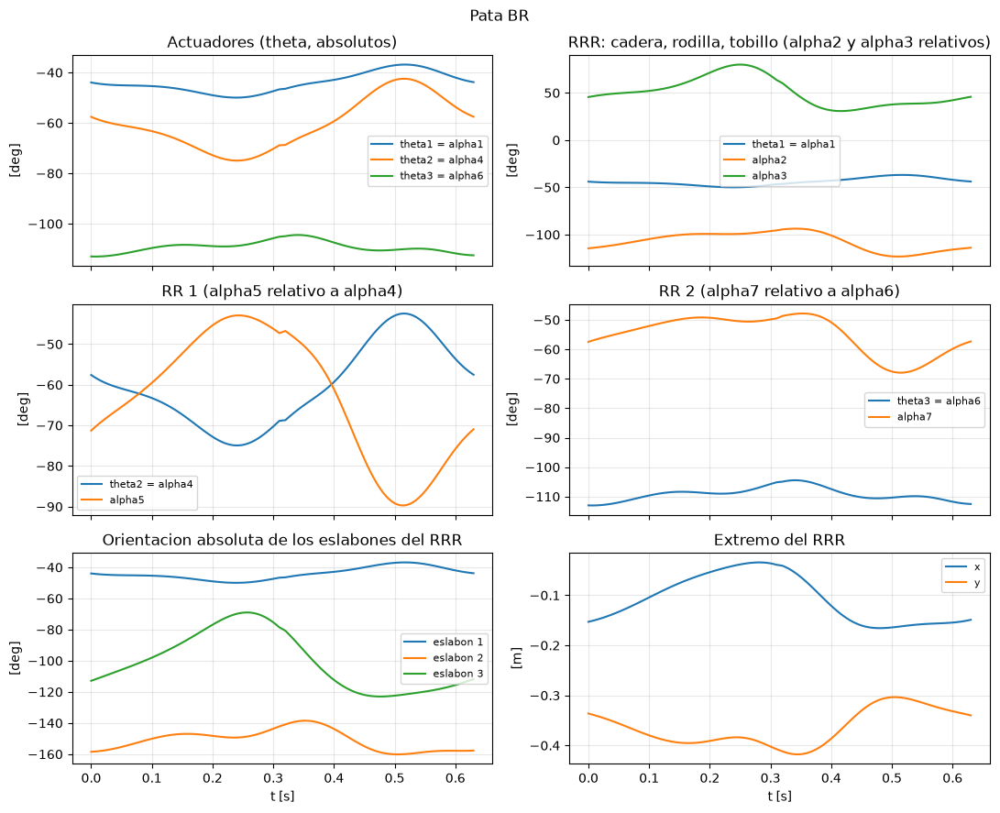

In [17]:
sol_br = resolver_trayectoria(res_br)
graficar_angulos(res_br, sol_br)

### 5.6 Animación

Animación del mecanismo completo siguiendo la trayectoria. Se guarda también como `mecanismo_br.gif` junto al notebook.

In [18]:
animar(res_br, sol_br)

## 6. Resumen

Eslabones de las dos patas en una sola tabla (los del RRR son fijos y los de los RR salen del dimensionado), y comparación de los puntos de acople y de la longitud total de los RR.

In [19]:
resumen = pd.concat([tabla_fr, tabla_br], ignore_index=True)
display(resumen)

comparacion = pd.DataFrame({
    'pata': [res_fr['nombre'], res_br['nombre']],
    'f1 (RR 1)': [res_fr['f1_opt'], res_br['f1_opt']],
    'f2 (RR 2)': [res_fr['f2_opt'], res_br['f2_opt']],
    'l1 = l2 [mm]': [round(res_fr['l'][0]*1000, 1), round(res_br['l'][0]*1000, 1)],
    'l3 = l4 [mm]': [round(res_fr['l'][2]*1000, 1), round(res_br['l'][2]*1000, 1)],
    'longitud total RR [mm]': [round(2*(res_fr['l'][0] + res_fr['l'][2])*1000, 1), round(2*(res_br['l'][0] + res_br['l'][2])*1000, 1)],
})
comparacion

,pata,eslabon,mecanismo,tipo,longitud [m],f (acople),longitud [mm]
0,FR,r1,RRR principal (eslabon 1),fijo,0.1210,NaN,121.0
1,FR,r2,RRR principal (eslabon 2),fijo,0.1110,NaN,111.0
2,FR,r3,RRR principal (eslabon 3),fijo,0.1534,NaN,153.4
3,FR,l1,"RR 1, acoplado al eslabon 2",optimizado,0.1008,0.45,100.8
4,FR,l2,"RR 1, acoplado al eslabon 2",optimizado,0.1008,0.45,100.8
5,FR,l3,"RR 2, acoplado al eslabon 3",optimizado,0.1601,0.20,160.1
6,FR,l4,"RR 2, acoplado al eslabon 3",optimizado,0.1601,0.20,160.1
7,BR,r1,RRR principal (eslabon 1),fijo,0.1660,NaN,166.0
8,BR,r2,RRR principal (eslabon 2),fijo,0.2310,NaN,231.0
9,BR,r3,RRR principal (eslabon 3),fijo,0.1480,NaN,148.0


,pata,f1 (RR 1),f2 (RR 2),l1 = l2 [mm],l3 = l4 [mm],longitud total RR [mm]
0,FR,0.45,0.2,100.8,160.1,521.7
1,BR,0.20,0.2,81.4,209.1,581.1
